# Pengaruh Berita Geopolitik terhadap Kurs USD/IDR (Kurs Transaksi BI)

**Pertanyaan penelitian.** Apakah sentimen dan topik berita geopolitik (CNBC) menambah daya prediksi
*log return* harian kurs tengah USD/IDR Bank Indonesia, dibandingkan model yang hanya memakai riwayat kurs?

**Hipotesis.**
- H0: menambahkan fitur berita **tidak** menurunkan galat prediksi out-of-sample dibandingkan fitur return saja.
- H1: fitur berita menurunkan galat prediksi secara signifikan (uji Diebold–Mariano).

**Data.**
- `data/raw/cnbc_with_published.csv` : hasil scraping berita CNBC per kata kunci geopolitik.
- `data/raw/bi-usd-rate.csv` : kurs jual & beli transaksi BI (USD), harian.
- Periode: 1 September 2021 – 1 September 2026.

**Alur notebook.** Setup → Muat data → Timestamp → Cleaning berita → Cleaning kurs → Preprocessing teks
→ Sentimen → Penyelarasan berita ke tanggal kurs → Agregasi harian → EDA → Fitur & target → Split
→ Modelling (ablation + walk-forward) → Evaluasi & uji signifikansi → Kesimpulan.

### Catatan perubahan dari versi sebelumnya

| # | Masalah di versi lama | Perbaikan |
|---|---|---|
| 1 | `date_raw` dianggap UTC lalu dikonversi ke WIB, sehingga `tanggal`/`jam` meleset **+7 jam**. Padahal `date_raw` sudah WIB (`published_raw` 07:28 UTC = `date_raw` 2:28 PM). | Diverifikasi langsung di notebook. `ts_wib` = `published_raw`→WIB, fallback `date_raw` (sudah WIB). |
| 2 | Cutoff tidak konsisten (komentar 15:15, kode 15:00), libur nasional tidak ditangani, `holidays` tidak dipakai. | Berita dipetakan ke **tanggal kurs BI berikutnya yang benar-benar ada** (`merge_asof`), sehingga akhir pekan & libur otomatis tertangani. Jam penetapan kurs jadi parameter `RATE_FIX_TIME`. |
| 3 | Dedup URL tidak berfungsi (URL membawa `?&qsearchterm=...`). | Query string dibuang sebelum dedup; semua keyword pencarian artikel yang sama digabung. |
| 4 | Filter relevansi tidak membuang apa pun (`keyword_matched` selalu terisi). | Relevansi dicek dari isi teks (judul/ringkasan, atau ≥N kemunculan di badan berita). |
| 5 | Kata menempel dari scraping (`asgeopoliticalrisks`). | Dipecah ulang secara aman memakai kosakata korpus. |
| 6 | Stopword membuang `us`/`not`/`no`; lemmatizer mengubah `us`→`u`. | `U.S.`→`usa`, negasi & kata arah dipertahankan, entitas dilindungi dari lemmatisasi. POS tagging dilakukan **sebelum** stopword dibuang. |
| 7 | Hasil lemmatisasi tidak dipakai (TF-IDF memakai teks non-lemma). Judul digandakan tanpa alasan. | TF-IDF memakai teks lemma; judul tidak digandakan; ringkasan tidak diulang bila identik dengan awal badan berita. |
| 8 | Hari tanpa berita = VADER 0, tidak bisa dibedakan dari berita netral. | Tambah fitur `has_news`; rolling sentimen dibobot jumlah berita. |
| 9 | 2.000 fitur TF-IDF untuk 837 baris train (p > n). | TF-IDF → TruncatedSVD (20 komponen) di dalam `Pipeline`, sehingga di-fit ulang hanya pada data train di setiap fold (bebas leakage). |
| 10 | Tidak ada ablation; satu split; tidak ada uji signifikansi; grid Ridge mentok di ujung. | Ablation 4 set fitur, grid lebih lebar + peringatan ujung grid, refit train+val sebelum test, walk-forward, uji Diebold–Mariano, balanced accuracy & MCC. |
| 11 | Merge memakai `bi_raw` bukan `bi` yang sudah dibersihkan; sel duplikat menimpa `merged_data_clean`; urutan eksekusi acak. | Diperbaiki; satu alur linear yang dapat dijalankan dengan *Restart & Run All*. |
| 12 | Output menampilkan dataframe penuh (file .ipynb ~40 MB). | Hanya menampilkan kolom/baris yang relevan. |

## 0. Setup & konfigurasi
Semua parameter penting dikumpulkan di satu tempat supaya mudah diubah dan dilaporkan.

In [1]:
import re
import html
import warnings
from collections import Counter
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller

import nltk
from nltk import pos_tag
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from langdetect import detect, DetectorFactory, LangDetectException

import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import ParameterGrid
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             balanced_accuracy_score, matthews_corrcoef)
import joblib

# Hanya FutureWarning yang disembunyikan; warning lain (mis. konvergensi) tetap tampil.
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 110

for pkg in ["stopwords", "wordnet", "omw-1.4", "averaged_perceptron_tagger_eng", "vader_lexicon"]:
    nltk.download(pkg, quiet=True)

print("pandas", pd.__version__, "| numpy", np.__version__, "| sklearn", sklearn.__version__, "| nltk", nltk.__version__)

pandas 2.2.3 | numpy 2.2.6 | sklearn 1.8.0 | nltk 3.9.1


In [2]:
# ===================== KONFIGURASI =====================
RAW_NEWS = Path("data/raw/cnbc_with_published.csv")
RAW_BI   = Path("data/raw/bi-usd-rate.csv")
OUT_DIR  = Path("data/processed")

TZ         = "Asia/Jakarta"
START_DATE = pd.Timestamp("2021-09-01")
END_DATE   = pd.Timestamp("2026-09-01 23:59:59")

# Jam penetapan kurs transaksi BI (mengacu JISDOR) dalam WIB.
# Berita yang terbit SEBELUM jam ini dianggap sudah tercermin di kurs hari itu;
# berita SETELAHNYA dipetakan ke tanggal kurs berikutnya.
# >>> Verifikasi jam ini ke sumber resmi BI dan sebutkan sumbernya di laporan. <<<
RATE_FIX_TIME = "10:00"

MIN_WORDS      = 350   # panjang minimum badan berita (kata); lihat distribusi di bagian 3
MIN_BODY_HITS  = 3     # min. kemunculan kata kunci di badan berita jika judul/ringkasan tidak memuatnya
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15

TFIDF_PARAMS   = dict(ngram_range=(1, 2), min_df=5, max_df=0.9, max_features=3000, sublinear_tf=True)
SVD_COMPONENTS = 20
WALK_STEP      = 20    # walk-forward: refit setiap 20 hari bursa
RANDOM_STATE   = 42

DetectorFactory.seed = RANDOM_STATE
np.random.seed(RANDOM_STATE)

## 1. Memuat data

In [3]:
news_raw = pd.read_csv(RAW_NEWS)
bi_raw   = pd.read_csv(RAW_BI)

print("Berita :", news_raw.shape)
print("Kurs BI:", bi_raw.shape)
print("\nStatus scraping:\n", news_raw["scrape_status"].value_counts(dropna=False).to_string())
news_raw[["keyword_matched", "title", "date_raw", "published_raw", "section", "scrape_status"]].head()

Berita : (16733, 13)
Kurs BI: (1202, 5)

Status scraping:
 scrape_status
ok                                                                                                                                                                                                        15239
not_found                                                                                                                                                                                                  1486
error: 500 Server Error: Internal Server Error for url: https://www.cnbc.com/2024/10/11/jpmorgan-chase-jpm-earnings-q3-2024.html?&qsearchterm=geopolitical%20risk                                             1
error: 404 Client Error: Not Found for url: https://www.cnbc.com/2018/04/12/the-associated-press-world-stocks-oil-price-stabilize-amid-geopolitical-concerns.html?&qsearchterm=geopolitical%20risk            1
error: 404 Client Error: Not Found for url: https://www.cnbc.com/2018/04/12/the-associated-pres

,keyword_matched,title,date_raw,published_raw,section,scrape_status
0,geopolitical risk,Global shipping authorities warn of maritime trade breakdown amidgeopoliticalturmoil,9/8/2026 2:28:41 PM,2026-09-08T07:28:41+0000,Markets,ok
1,geopolitical risk,Morning Call Sheet: AI rebound meets risinggeopoliticalrisks,7/31/2026 5:58:53 PM,NaN,Morning Call,not_found
2,geopolitical risk,"Global markets keep shrugging off shocks. Here’s what could break that streak, according to HSBC",9/8/2026 11:02:43 AM,2026-09-08T04:02:43+0000,World Markets,ok
3,geopolitical risk,"Yen hovers near seven-month high, dollar steadies",9/8/2026 11:17:07 AM,2026-09-08T04:17:07+0000,Currencies,ok
4,geopolitical risk,Central banks are bringing gold reserves home asgeopoliticalrisks rise,6/17/2026 2:28:36 PM,2026-06-17T07:28:36+0000,Gold,ok


## 2. Timestamp berita (WIB)

Ada dua sumber waktu: `date_raw` (tanpa zona waktu) dan `published_raw` (ISO, UTC).
Sel di bawah **memverifikasi** zona waktu `date_raw` dengan menghitung selisihnya terhadap `published_raw`
yang sudah dikonversi ke WIB. Jika selisihnya ≈ 0 jam, berarti `date_raw` sudah WIB dan **tidak boleh** dikonversi lagi.

In [4]:
def parse_date_raw(s: pd.Series) -> pd.Series:
    """Parse 'M/D/YYYY h:mm:ss AM/PM'; baris yang gagal dicoba dengan parser umum."""
    dt = pd.to_datetime(s, format="%m/%d/%Y %I:%M:%S %p", errors="coerce")
    gagal = dt.isna() & s.notna()
    if gagal.any():
        dt = dt.where(~gagal, pd.to_datetime(s.where(gagal), errors="coerce", format="mixed"))
    return dt

news_raw["date_raw_dt"] = parse_date_raw(news_raw["date_raw"])
news_raw["published_wib"] = (
    pd.to_datetime(news_raw["published_raw"], utc=True, errors="coerce")
      .dt.tz_convert(TZ).dt.tz_localize(None)
)

selisih_jam = ((news_raw["date_raw_dt"] - news_raw["published_wib"]).dt.total_seconds() / 3600).dropna()
print("Selisih date_raw - published_raw(WIB) dalam jam (5 nilai terbanyak):")
print(selisih_jam.round(2).value_counts().head().to_string())
porsi_sama = (selisih_jam.abs() < 1 / 60).mean()
print(f"\nPorsi baris dengan selisih < 1 menit: {porsi_sama:.1%}")
if porsi_sama > 0.95:
    print("=> date_raw SUDAH dalam WIB. Tidak perlu (dan tidak boleh) dikonversi ulang.")
else:
    print("=> PERHATIAN: date_raw tidak konsisten dengan WIB. Periksa sebelum melanjutkan!")

# Timestamp kanonik: published_raw (eksplisit UTC) bila ada, jika tidak pakai date_raw (sudah WIB).
news_raw["ts_wib"] = news_raw["published_wib"].fillna(news_raw["date_raw_dt"])
news_raw["ts_source"] = np.where(news_raw["published_wib"].notna(), "published_raw", "date_raw")
print("\nSumber timestamp:\n", news_raw["ts_source"].value_counts().to_string())
print("Timestamp gagal di-parse:", news_raw["ts_wib"].isna().sum())

Selisih date_raw - published_raw(WIB) dalam jam (5 nilai terbanyak):
 0.00     15222
-11.75        4
-5.54         3
-1.60         2
-15.51        2

Porsi baris dengan selisih < 1 menit: 99.9%
=> date_raw SUDAH dalam WIB. Tidak perlu (dan tidak boleh) dikonversi ulang.

Sumber timestamp:
 ts_source
published_raw    15239
date_raw          1494
Timestamp gagal di-parse: 0


## 3. Cleaning data berita
Setiap tahap mencatat jumlah baris supaya alur penyaringan dapat dilaporkan (lihat tabel di akhir bagian ini).

In [5]:
langkah = []
def catat(tahap: str, df: pd.DataFrame) -> None:
    langkah.append((tahap, len(df)))
    print(f"{tahap:<55}: {len(df):>6}")

news = news_raw.copy()
catat("Data awal", news)

# 3.1 Rentang tanggal (memakai timestamp WIB kanonik)
news = news[news["ts_wib"].between(START_DATE, END_DATE)]
catat("Filter rentang 2021-09-01 s.d. 2026-09-01", news)

# 3.2 Dedup URL TANPA query string (?&qsearchterm=... membuat URL yang sama tampak unik)
news["url_clean"] = news["url"].str.split("?").str[0].str.rstrip("/").str.lower()
kw_per_url = (news.groupby("url_clean")["keyword_matched"]
                  .agg(lambda s: " | ".join(sorted(set(s.dropna())))))
news = news.sort_values("ts_wib").drop_duplicates("url_clean", keep="first")
news["keywords_all"] = news["url_clean"].map(kw_per_url)
catat("Dedup URL (tanpa query string)", news)

# 3.3 Dedup judul + timestamp (artikel sama dengan URL berbeda)
news = news.drop_duplicates(subset=["title", "ts_wib"], keep="first")
catat("Dedup judul + timestamp", news)

# 3.4 Konten multimedia: dilihat dari PATH URL dan section, bukan kata di judul
#     (versi lama membuang artikel teks sah yang judulnya memuat kata "live"/"image").
MEDIA_URL_RE = r"cnbc\.com/(?:video|videos|pictures|photos|gallery|podcast|podcasts|audio)/"
MEDIA_SECTION_RE = r"\b(?:video|videos|podcast|podcasts|audio|gallery|pictures)\b"
mask_media = (news["url_clean"].str.contains(MEDIA_URL_RE, regex=True)
              | news["section"].fillna("").str.contains(MEDIA_SECTION_RE, case=False, regex=True))
news = news.loc[~mask_media]
catat("Buang video/podcast/galeri", news)

# 3.5 Badan berita kosong (umumnya scraping gagal)
print("   -> status scraping pada full_text kosong:",
      news.loc[news["full_text"].isna(), "scrape_status"].value_counts().to_dict())
news = news.dropna(subset=["full_text"])
catat("Buang full_text kosong", news)

Data awal                                              :  16733
Filter rentang 2021-09-01 s.d. 2026-09-01              :   8871
Dedup URL (tanpa query string)                         :   6817
Dedup judul + timestamp                                :   6817
Buang video/podcast/galeri                             :   6019
   -> status scraping pada full_text kosong: {'ok': 1281}
Buang full_text kosong                                 :   4738


### 3.6 Membersihkan artefak scraping
- Boilerplate CNBC (`In this article ... Follow your favorite stocks CREATE FREE ACCOUNT`) dan karakter lebar-nol dibuang.
- **Kata menempel** seperti `asgeopoliticalrisks` / `amidgeopoliticalturmoil` muncul karena highlight kata kunci
  di halaman pencarian menelan spasi. Kata dipecah **hanya jika** semua potongannya ada di kosakata korpus
  (dibangun dari badan berita), sehingga kata sah seperti *globalization* tidak ikut terpecah.

In [6]:
ZERO_WIDTH_RE  = re.compile("[​‌‍⁠﻿­]")
BOILERPLATE_RE = re.compile(r"^\s*In this article\b|Follow your favorite stocks\s*CREATE FREE ACCOUNT", re.I)
MULTI_SPACE_RE = re.compile(r"\s+")

def clean_raw(text) -> str:
    if not isinstance(text, str):
        return ""
    t = html.unescape(text)
    t = ZERO_WIDTH_RE.sub(" ", t)
    t = BOILERPLATE_RE.sub(" ", t)
    return MULTI_SPACE_RE.sub(" ", t).strip()

for col in ["title", "preview_summary", "full_text"]:
    news[f"{col}_clean"] = news[col].apply(clean_raw)

# Kosakata dari badan berita (frekuensi >= 3)
vocab_counter = Counter()
for t in news["full_text_clean"]:
    vocab_counter.update(re.findall(r"[a-z]+", t.lower()))
VOCAB = {w for w, c in vocab_counter.items() if c >= 3}

# Kandidat kata yang ter-highlight = kata dari kata kunci pencarian (>= 4 huruf)
HIGHLIGHT_TERMS = sorted(
    {w for kw in news_raw["keyword_matched"].dropna().unique() for w in kw.lower().split() if len(w) >= 4}
    | {"geopolitical", "geopolitics"},
    key=len, reverse=True,
)

@lru_cache(maxsize=None)
def split_glued(word: str):
    """Pecah `word` menjadi kata-kata valid di sekitar HIGHLIGHT_TERMS. None jika tidak bisa."""
    low = word.lower()
    if low in VOCAB:
        return (word,)
    for term in HIGHLIGHT_TERMS:
        i = low.find(term)
        if i == -1:
            continue
        pieces, ok = [], True
        for j, p in enumerate((word[:i], word[i:i + len(term)], word[i + len(term):])):
            if not p:
                continue
            if j == 1:
                pieces.append(p)
                continue
            sub = split_glued(p) if len(p) >= 2 else None
            if sub is None:
                ok = False
                break
            pieces.extend(sub)
        if ok and len(pieces) > 1:
            return tuple(pieces)
    return None

contoh_perbaikan = Counter()
def fix_glued(text: str) -> str:
    def repl(m):
        w = m.group(0)
        if w.lower() in VOCAB:
            return w
        parts = split_glued(w)
        if parts and len(parts) > 1:
            contoh_perbaikan[w] += 1
            return " ".join(parts)
        return w
    return re.sub(r"[A-Za-z]{8,}", repl, text)

for col in ["title_clean", "preview_summary_clean", "full_text_clean"]:
    news[col] = news[col].apply(fix_glued)

print("Jumlah kata menempel yang diperbaiki:", sum(contoh_perbaikan.values()))
print("Contoh:", [f"{w} -> {' '.join(split_glued(w))}" for w, _ in contoh_perbaikan.most_common(8)])

Jumlah kata menempel yang diperbaiki: 1022
Contoh: ['Eastconflict -> East conflict', 'Iranconflict -> Iran conflict', 'theconflictin -> the conflict in', 'theglobaleconomy -> the global economy', 'Ukraineconflict -> Ukraine conflict', 'escalatingconflictin -> escalating conflict in', 'andgeopoliticaltensions -> and geopolitical tensions', 'theriskof -> the risk of']


count     4738.0
mean       720.0
std        424.0
min         46.0
10%        340.0
25%        447.0
50%        639.0
75%        885.0
90%       1171.0
max      12025.0


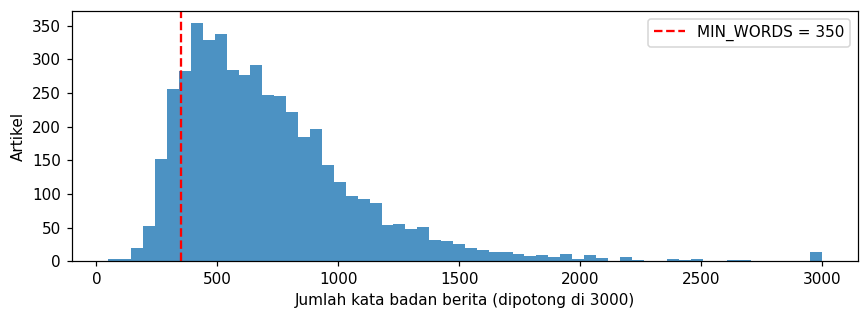

Panjang badan berita >= 350 kata                       :   4208


In [7]:
# 3.7 Panjang badan berita: lihat distribusinya dulu sebelum memilih ambang
news["n_words"] = news["full_text_clean"].str.split().str.len()
print(news["n_words"].describe(percentiles=[.1, .25, .5, .75, .9]).round(0).to_string())

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(news["n_words"].clip(upper=3000), bins=60, color="tab:blue", alpha=.8)
ax.axvline(MIN_WORDS, color="red", ls="--", label=f"MIN_WORDS = {MIN_WORDS}")
ax.set_xlabel("Jumlah kata badan berita (dipotong di 3000)"); ax.set_ylabel("Artikel"); ax.legend()
plt.tight_layout(); plt.show()

news = news.loc[news["n_words"] >= MIN_WORDS]
catat(f"Panjang badan berita >= {MIN_WORDS} kata", news)

In [8]:
# 3.8 Relevansi dicek dari ISI teks (bukan dari keyword_matched yang selalu terisi)
RELEVANCE_KEYWORDS = [
    "geopolitics", "geopolitical", "armed conflict", "global conflict", "international conflict",
    "military tensions", "national security", "sanctions", "trade war", "tariffs", "embargo",
    "export controls", "protectionism", "supply chain disruption", "diplomacy", "foreign policy",
    "nato", "brics", "opec", "g7", "war", "invasion", "ceasefire", "missile", "military",
]
RELEVANCE_KEYWORDS += [k.lower() for k in news_raw["keyword_matched"].dropna().unique()]
KW_RE = re.compile(
    r"\b(?:" + "|".join(re.escape(k).replace(r"\ ", r"\s+")
                         for k in sorted(set(RELEVANCE_KEYWORDS), key=len, reverse=True)) + r")s?\b",
    re.I,
)

head_hits = (news["title_clean"] + " " + news["preview_summary_clean"]).str.count(KW_RE)
body_hits = news["full_text_clean"].str.count(KW_RE)
mask_relevant = (head_hits >= 1) | (body_hits >= MIN_BODY_HITS)

print(f"Artikel tidak relevan: {(~mask_relevant).sum()}. Contoh yang DIBUANG:")
if (~mask_relevant).any():
    print(news.loc[~mask_relevant, "title_clean"].head(8).to_string())
news = news.loc[mask_relevant]
catat("Relevan (judul/ringkasan atau badan berita)", news)

# 3.9 Section yang tidak relevan
EXCLUDE_SECTIONS = {
    "sports", "entertainment", "television", "lifestyle", "travel", "food retail",
    "beer, wine & spirits", "college", "modern medicine", "life changes", "fashion", "celebrity",
}
news = news.loc[~news["section"].fillna("").str.lower().isin(EXCLUDE_SECTIONS)]
catat("Buang section non-ekonomi/politik", news)

# 3.10 Bahasa (deteksi pada judul + ringkasan, lebih cepat dan cukup akurat)
def detect_language(text: str) -> str:
    try:
        return detect(text) if len(text) >= 20 else "unknown"
    except LangDetectException:
        return "unknown"

news["lang"] = (news["title_clean"] + ". " + news["preview_summary_clean"]).apply(detect_language)
print("   -> distribusi bahasa:", news["lang"].value_counts().to_dict())
news = news.loc[news["lang"] == "en"].reset_index(drop=True)
catat("Bahasa Inggris", news)

pd.DataFrame(langkah, columns=["Tahap", "Jumlah artikel"])

Artikel tidak relevan: 1269. Contoh yang DIBUANG:
14943               What to watch today: Dow, S&P 500 set to bounce after four sessions of losses
13407              As many return to the office, tensions flare between the ‘vaxxed and unvaxxed’
16152                   Biden to host leaders of Australia, India, Japan at White House next week
14945                               More workers are facing mandatory Covid vaccination or no job
14946           What to watch today: Dow futures shoot up, turn positive after key inflation data
14947    FDIC teams up with Microsoft and Truist to create fund to invest in minority-owned banks
11774      After years of being ‘squeaky clean,’ the Federal Reserve is surrounded by controversy
16154          John Kerry says the U.S. can recover from Trump’s ‘sheer idiocy’ on climate change
Relevan (judul/ringkasan atau badan berita)            :   2939
Buang section non-ekonomi/politik                      :   2938
   -> distribusi bahasa: {'en': 2938}


,Tahap,Jumlah artikel
0,Data awal,16733
1,Filter rentang 2021-09-01 s.d. 2026-09-01,8871
2,Dedup URL (tanpa query string),6817
3,Dedup judul + timestamp,6817
4,Buang video/podcast/galeri,6019
5,Buang full_text kosong,4738
6,Panjang badan berita >= 350 kata,4208
7,Relevan (judul/ringkasan atau badan berita),2939
8,Buang section non-ekonomi/politik,2938
9,Bahasa Inggris,2938


## 4. Cleaning data kurs BI

In [9]:
def clean_numeric(series: pd.Series) -> pd.Series:
    """Hapus pemisah ribuan lalu konversi ke float."""
    return pd.to_numeric(series.astype(str).str.replace(",", "", regex=False).str.strip(), errors="coerce")

bi = bi_raw.copy()
bi["Tanggal"] = pd.to_datetime(bi["Tanggal"], errors="coerce", format="mixed").dt.normalize()
for c in ["Kurs Jual", "Kurs Beli", "NO", "Nilai"]:
    bi[c] = clean_numeric(bi[c])

# Cek format tanggal: kolom NO berurutan mundur waktu. Jika ini gagal, kemungkinan
# tanggal ter-parse sebagai hari/bulan terbalik -> tentukan `format=` secara eksplisit.
assert bi.sort_values("NO")["Tanggal"].is_monotonic_decreasing, "Urutan tanggal tidak konsisten dengan kolom NO"
assert (bi["Nilai"] == 1).all(), "Ada kurs yang tidak per 1 USD"

print(f"Baris awal                : {len(bi)}")
bi = bi.loc[bi["Tanggal"].between(START_DATE, END_DATE)]
print(f"Filter rentang tanggal    : {len(bi)}")
bi = bi.loc[bi["Kurs Jual"].gt(0) & bi["Kurs Beli"].gt(0)]
print(f"Kurs numerik & positif    : {len(bi)}")
bi = bi.loc[bi["Kurs Jual"] > bi["Kurs Beli"]]
print(f"Kurs Jual > Kurs Beli     : {len(bi)}")
bi = bi.sort_values("Tanggal").drop_duplicates("Tanggal", keep="last").reset_index(drop=True)
print(f"Dedup tanggal             : {len(bi)}")

bi["kurs_mid"] = (bi["Kurs Jual"] + bi["Kurs Beli"]) / 2
bi["ret"] = np.log(bi["kurs_mid"]).diff()          # log return (tanggal kurs sebelumnya -> hari ini)

spread = bi["Kurs Jual"] / bi["Kurs Beli"] - 1
print(f"\nSpread jual/beli: min {spread.min():.4%}, median {spread.median():.4%}, max {spread.max():.4%}")
gap = bi["Tanggal"].diff().dt.days
print("Jarak antar tanggal kurs (hari):", gap.value_counts().sort_index().to_dict())
print("Jarak > 4 hari (libur panjang):")
print(bi.loc[gap > 4, ["Tanggal"]].assign(gap_hari=gap[gap > 4]).to_string(index=False))

Baris awal                : 1202
Filter rentang tanggal    : 1202
Kurs numerik & positif    : 1202
Kurs Jual > Kurs Beli     : 1202
Dedup tanggal             : 1202

Spread jual/beli: min 1.0050%, median 1.0050%, max 1.0051%
Jarak antar tanggal kurs (hari): {1.0: 922, 2.0: 18, 3.0: 223, 4.0: 18, 5.0: 13, 6.0: 2, 8.0: 2, 11.0: 2, 12.0: 1}
Jarak > 4 hari (libur panjang):
   Tanggal  gap_hari
2022-05-09      11.0
2023-04-26       8.0
2023-06-05       5.0
2023-07-03       6.0
2023-12-27       5.0
2024-02-12       5.0
2024-03-13       5.0
2024-04-16      11.0
2024-05-13       5.0
2024-05-27       5.0
2024-06-19       5.0
2025-01-30       6.0
2025-04-08      12.0
2025-05-14       5.0
2025-06-02       5.0
2025-06-10       5.0
2025-12-29       5.0
2026-02-18       5.0
2026-03-25       8.0
2026-05-18       5.0


## 5. Preprocessing teks
Urutan: normalisasi → lowercase → **POS tagging pada kalimat utuh** → buang stopword → lemmatisasi.
POS tagging dilakukan sebelum stopword dibuang karena tagger bergantung pada konteks kata di sekitarnya.

Keputusan penting:
- `U.S.`/`US` → `usa`, `U.K.` → `uk`, `E.U.` → `eu`, `U.N.` → `un`, supaya tidak tertukar dengan kata ganti *us*.
- Negasi (`not`, `no`, `nor`) dan kata arah (`up`, `down`, `above`, `below`, `against`) **dipertahankan**.
- Entitas (`usa`, `nato`, `opec`, `brics`, ...) tidak dilemmatisasi (mencegah `brics`→`bric`, `us`→`u`).
- Angka murni dibuang (tidak bermakna sebagai fitur topik).
- Judul **tidak** digandakan; ringkasan hanya ditambahkan jika tidak identik dengan awal badan berita.

In [10]:
ABBREVIATIONS = [
    (re.compile(r"\bU\.S\.(?:A\.)?"), " USA "),
    (re.compile(r"\bUS\b"), " USA "),
    (re.compile(r"\bU\.K\."), " UK "),
    (re.compile(r"\bE\.U\."), " EU "),
    (re.compile(r"\bU\.N\."), " UN "),
]
URL_RE      = re.compile(r"http\S+|www\.\S+")
EMAIL_RE    = re.compile(r"\S+@\S+\.\S+")
HTML_TAG_RE = re.compile(r"<[^>]+>")
POSSESSIVE_RE = re.compile(r"[’']s\b")
NEGATION_RE   = re.compile(r"n[’']t\b")
CURRENCY_WORDS = {"%": " percent ", "$": " dollar ", "£": " pound ", "€": " euro ", "¥": " yen "}
CURRENCY_RE = re.compile("|".join(re.escape(s) for s in CURRENCY_WORDS))
NON_ALNUM_RE = re.compile(r"[^a-zA-Z0-9\s]")

def normalize_text(text: str) -> str:
    t = HTML_TAG_RE.sub(" ", text)
    t = URL_RE.sub(" ", t)
    t = EMAIL_RE.sub(" ", t)
    for pat, rep in ABBREVIATIONS:
        t = pat.sub(rep, t)
    t = POSSESSIVE_RE.sub("", t)          # China's -> China
    t = NEGATION_RE.sub(" not", t)        # wouldn't -> would not
    t = CURRENCY_RE.sub(lambda m: CURRENCY_WORDS[m.group(0)], t)
    t = NON_ALNUM_RE.sub(" ", t)
    return MULTI_SPACE_RE.sub(" ", t).strip().lower()

KEEP_WORDS = {"not", "no", "nor", "against", "up", "down", "above", "below", "over", "under"}
CUSTOM_STOPWORDS = {"cnbc", "article", "read", "also", "said", "says", "say",
                    "would", "could", "one", "two", "get", "got", "mr", "ms"}
STOPWORDS_EN = (set(stopwords.words("english")) | CUSTOM_STOPWORDS) - KEEP_WORDS
PROTECTED = {"usa", "uk", "eu", "un", "nato", "opec", "brics", "g7", "g20", "imf", "fed", "ecb", "yuan", "rupiah"}

lemmatizer = WordNetLemmatizer()
POS_MAP = {"J": wordnet.ADJ, "V": wordnet.VERB, "N": wordnet.NOUN, "R": wordnet.ADV}

def preprocess(text: str) -> list:
    tokens = text.split()
    if not tokens:
        return []
    out = []
    for tok, tag in pos_tag(tokens):
        if tok in STOPWORDS_EN or len(tok) < 2 or tok.isdigit():
            continue
        out.append(tok if tok in PROTECTED else lemmatizer.lemmatize(tok, POS_MAP.get(tag[0], wordnet.NOUN)))
    return out

def build_document(row) -> str:
    body, summ = row["full_text_clean"], row["preview_summary_clean"]
    parts = [row["title_clean"]]
    if summ and not body.lower().startswith(summ[:80].lower()):
        parts.append(summ)
    parts.append(body)
    return ". ".join(parts)

news["normalized_text"] = news.apply(build_document, axis=1).apply(normalize_text)
news["tokens"] = news["normalized_text"].apply(preprocess)      # butuh beberapa menit
news["text_lemmatized"] = news["tokens"].apply(" ".join)

print(f"Rata-rata kata setelah normalisasi : {news['normalized_text'].str.split().str.len().mean():.1f}")
print(f"Rata-rata token setelah preprocess : {news['tokens'].str.len().mean():.1f}")
news[["title_clean", "text_lemmatized"]].head(3)

Rata-rata kata setelah normalisasi : 826.7
Rata-rata token setelah preprocess : 486.2


,title_clean,text_lemmatized
0,"Inflation could repeat the 1960s, when the Fed lost control, Niall Ferguson says",inflation repeat 1960s fed lose control niall ferguson inflation repeat trajectory late 1960s la...
1,"Guinea coup rattles iron ore and bauxite markets, stokes economic uncertainty",guinea coup rattle iron ore bauxite market stoke economic uncertainty military junta claim seize...
2,Op-ed: A key choice awaits China — money or principles,op ed key choice awaits china money principle china crucial moment political economic evolution ...


In [11]:
# Sanity check: kata penting tidak boleh hilang / rusak
all_tokens = Counter(t for toks in news["tokens"] for t in toks)
for w in ["usa", "not", "geopolitical", "sanction", "tariff", "war", "u", "bric"]:
    print(f"{w:<13} {all_tokens.get(w, 0):>8}")
print("(`u` dan `bric` seharusnya ~0: itu tanda lemmatisasi yang salah)")

usa              16573
not              11513
geopolitical      1967
sanction          1828
tariff            2799
war               7338
u                  631
bric                 1
(`u` dan `bric` seharusnya ~0: itu tanda lemmatisasi yang salah)


## 6. Sentimen (VADER)
VADER dihitung pada **judul yang sudah diperbaiki** (kata menempel sudah dipecah) dan pada ringkasan.
Keterbatasan: VADER dirancang untuk teks media sosial; kata seperti *tariff*, *sanction*, *risk* sering tidak
mendapat skor. Untuk pengembangan, pertimbangkan FinBERT atau leksikon Loughran–McDonald.

In [12]:
vader = SentimentIntensityAnalyzer()

def vader_score(t: str) -> float:
    return vader.polarity_scores(t)["compound"] if isinstance(t, str) and t.strip() else np.nan

news["vader_title"]   = news["title_clean"].apply(vader_score)
news["vader_summary"] = news["preview_summary_clean"].apply(vader_score)

print(news[["vader_title", "vader_summary"]].describe().round(3).to_string())
print(f"\nPorsi judul dengan skor tepat 0 (tidak ada kata bermuatan di leksikon): {(news['vader_title'] == 0).mean():.1%}")
news[["title_clean", "vader_title"]].head()

       vader_title  vader_summary
count     2938.000       2938.000
mean        -0.148         -0.107
std          0.394          0.448
min         -0.949         -0.949
25%         -0.477         -0.494
50%         -0.052         -0.016
75%          0.000          0.250
max          0.939          0.923

Porsi judul dengan skor tepat 0 (tidak ada kata bermuatan di leksikon): 24.8%


,title_clean,vader_title
0,"Inflation could repeat the 1960s, when the Fed lost control, Niall Ferguson says",-0.3182
1,"Guinea coup rattles iron ore and bauxite markets, stokes economic uncertainty",-0.3400
2,Op-ed: A key choice awaits China — money or principles,0.0772
3,"Biden, Xi discuss avoiding confrontation in second phone call of new U.S. administration",-0.5719
4,"‘We were naive’: Ex-CIA, military and diplomatic veterans reflect on lessons learned, 20 years a...",0.0000


## 7. Penyelarasan berita ke tanggal kurs BI

Setiap berita dipetakan ke **tanggal kurs BI pertama yang ditetapkan setelah berita terbit**
(`merge_asof`, arah maju, pada `Tanggal + RATE_FIX_TIME`). Konsekuensinya:
- Akhir pekan **dan libur nasional** otomatis tertangani, karena yang dipakai adalah tanggal kurs yang benar-benar ada.
- Berita pada baris tanggal *t* = berita yang terbit di antara penetapan kurs *t−1* dan *t*,
  sehingga semuanya **sudah diketahui** saat kurs *t* ditetapkan.
- Target = return *t → t+1*, sehingga tidak ada kebocoran informasi dari masa depan.

In [13]:
fix_h, fix_m = map(int, RATE_FIX_TIME.split(":"))
bi_fix = bi[["Tanggal"]].rename(columns={"Tanggal": "rate_date"})
bi_fix["fix_ts"] = (bi_fix["rate_date"] + pd.Timedelta(hours=fix_h, minutes=fix_m)).astype("datetime64[ns]")

news["ts_wib"] = news["ts_wib"].astype("datetime64[ns]")
news = pd.merge_asof(
    news.sort_values("ts_wib"), bi_fix.sort_values("fix_ts"),
    left_on="ts_wib", right_on="fix_ts",
    direction="forward", allow_exact_matches=False,
)
tanpa_kurs = news["rate_date"].isna().sum()
news = news.dropna(subset=["rate_date"]).reset_index(drop=True)
print(f"Berita setelah penetapan kurs terakhir (dibuang): {tanpa_kurs}")

lag_hari = (news["rate_date"] - news["ts_wib"].dt.normalize()).dt.days
print("Jarak tanggal terbit -> tanggal kurs (hari):", lag_hari.value_counts().sort_index().to_dict())

contoh = news.loc[lag_hari >= 3, ["ts_wib", "rate_date", "title_clean"]].head(5)
contoh.insert(1, "hari_terbit", contoh["ts_wib"].dt.day_name())
contoh  # contoh berita akhir pekan / sebelum libur

Berita setelah penetapan kurs terakhir (dibuang): 0
Jarak tanggal terbit -> tanggal kurs (hari): {0: 582, 1: 1579, 2: 250, 3: 363, 4: 76, 5: 31, 6: 21, 7: 14, 8: 9, 9: 1, 10: 2, 11: 8, 12: 2}


,ts_wib,hari_terbit,rate_date,title_clean
0,2021-09-03 17:07:08,Friday,2021-09-06,"Inflation could repeat the 1960s, when the Fed lost control, Niall Ferguson says"
3,2021-09-10 11:36:17,Friday,2021-09-13,"Biden, Xi discuss avoiding confrontation in second phone call of new U.S. administration"
7,2021-09-17 12:17:53,Friday,2021-09-20,Donors pledging billions in aid to Afghanistan face a challenge: Navigating the Taliban
13,2021-10-01 18:01:18,Friday,2021-10-04,"Europe needs to start thinking more like the U.S. on security, former German vice chancellor ..."
18,2021-10-08 10:53:35,Friday,2021-10-11,"The U.S. and China must manage ‘intense competition,’ top Biden advisor says"


In [14]:
def ratio_where(x, cond):
    x = x.dropna()
    return cond(x).mean() if len(x) else np.nan

daily_news = (
    news.groupby("rate_date")
        .agg(news_count=("title_clean", "size"),
             vader_title_mean=("vader_title", "mean"),
             vader_title_min=("vader_title", "min"),
             vader_title_max=("vader_title", "max"),
             vader_title_std=("vader_title", "std"),
             vader_title_pos_ratio=("vader_title", lambda x: ratio_where(x, lambda v: v > 0.05)),
             vader_title_neg_ratio=("vader_title", lambda x: ratio_where(x, lambda v: v < -0.05)),
             vader_summary_mean=("vader_summary", "mean"),
             text_lemmatized=("text_lemmatized", " ".join),
             titles=("title_clean", " | ".join))
        .reset_index()
)

# Merge ke data kurs yang SUDAH dibersihkan (`bi`, bukan `bi_raw`)
daily = bi.merge(daily_news, left_on="Tanggal", right_on="rate_date", how="left",
                 validate="one_to_one").drop(columns="rate_date")

VADER_COLS = [c for c in daily.columns if c.startswith("vader_")]
daily["has_news"]   = daily["news_count"].notna().astype(int)   # membedakan "tidak ada berita" dari "netral"
daily["news_count"] = daily["news_count"].fillna(0).astype(int)
daily[VADER_COLS]   = daily[VADER_COLS].fillna(0.0)
daily[["text_lemmatized", "titles"]] = daily[["text_lemmatized", "titles"]].fillna("")

print(daily.shape)
print(f"Hari kurs dengan berita: {daily['has_news'].mean():.1%}")
daily[["Tanggal", "kurs_mid", "ret", "news_count", "has_news", "vader_title_mean"]].tail()

(1202, 18)
Hari kurs dengan berita: 79.1%


,Tanggal,kurs_mid,ret,news_count,has_news,vader_title_mean
1197,2026-08-26,17703.0,-0.000113,1,1,-0.27320
1198,2026-08-27,17717.0,0.000791,1,1,-0.29600
1199,2026-08-28,17762.0,0.002537,2,1,0.00000
1200,2026-08-31,17703.0,-0.003327,5,1,-0.27866
1201,2026-09-01,17746.0,0.002426,2,1,-0.36335


## 8. Exploratory Data Analysis

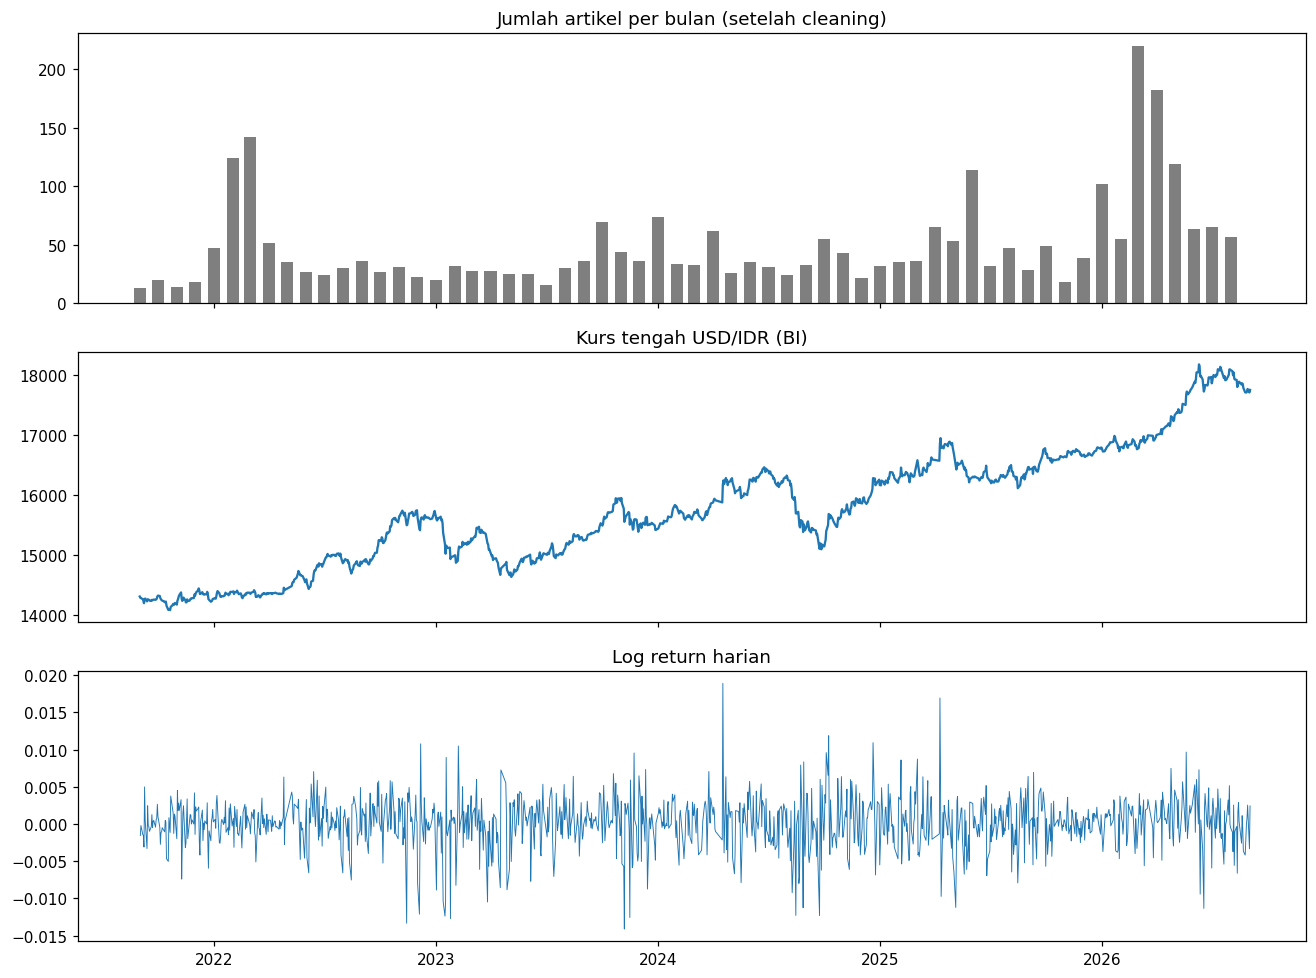

Artikel per tahun: {2021: 65, 2022: 598, 2023: 390, 2024: 472, 2025: 549, 2026: 864}
Porsi hari kurs dengan berita per tahun: {2021: 0.56, 2022: 0.79, 2023: 0.73, 2024: 0.78, 2025: 0.83, 2026: 0.97}


In [15]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
monthly = news.set_index("ts_wib").resample("MS").size()
axes[0].bar(monthly.index, monthly.values, width=20, color="tab:gray")
axes[0].set_title("Jumlah artikel per bulan (setelah cleaning)")
axes[1].plot(daily["Tanggal"], daily["kurs_mid"], color="tab:blue")
axes[1].set_title("Kurs tengah USD/IDR (BI)")
axes[2].plot(daily["Tanggal"], daily["ret"], color="tab:blue", lw=.6)
axes[2].set_title("Log return harian")
plt.tight_layout(); plt.show()

print("Artikel per tahun:", news["ts_wib"].dt.year.value_counts().sort_index().to_dict())
print("Porsi hari kurs dengan berita per tahun:",
      daily.groupby(daily["Tanggal"].dt.year)["has_news"].mean().round(2).to_dict())

> **Perhatikan:** jika jumlah berita jauh lebih banyak pada tahun-tahun terakhir, kemungkinan hasil pencarian
> CNBC bias ke artikel terbaru. Fitur berita menjadi **tidak stasioner** (distribusinya berbeda antara train
> dan test). Laporkan ini sebagai keterbatasan.

In [16]:
for name, s in [("kurs_mid", daily["kurs_mid"]), ("ret", daily["ret"].dropna())]:
    stat, p, *_ = adfuller(s, autolag="AIC")
    print(f"ADF {name:<9}: stat={stat:7.3f}, p={p:.4f} -> {'stasioner' if p < .05 else 'TIDAK stasioner'}")

r = daily["ret"].dropna()
print(f"\nReturn: mean={r.mean():.6f}, std={r.std():.6f}, skew={r.skew():.2f}, kurtosis={r.kurt():.2f}")
print(f"Porsi hari rupiah melemah (ret>0): {(r > 0).mean():.1%}")
print(f"Autokorelasi lag-1 return: {r.autocorr(1):.3f}")

ADF kurs_mid : stat= -0.572, p=0.8771 -> TIDAK stasioner
ADF ret      : stat=-12.104, p=0.0000 -> stasioner

Return: mean=0.000179, std=0.003335, skew=-0.32, kurtosis=3.01
Porsi hari rupiah melemah (ret>0): 55.4%
Autokorelasi lag-1 return: 0.097


### Korelasi berita: efek hari yang sama vs. efek prediktif
Korelasi dengan `ret` (return *t−1 → t*, periode yang sama dengan terbitnya berita) mengukur **reaksi**
kurs terhadap berita. Korelasi dengan `target` (return *t → t+1*) mengukur **daya prediksi**. Hanya hari yang memiliki berita yang dipakai.

In [17]:
tmp = daily.assign(target=daily["ret"].shift(-1)).query("has_news == 1").dropna(subset=["ret", "target"])
rows = []
for f in ["news_count"] + VADER_COLS:
    r1, p1 = stats.spearmanr(tmp[f], tmp["ret"])
    r2, p2 = stats.spearmanr(tmp[f], tmp["target"])
    rows.append({"fitur": f, "rho_ret_hari_sama": r1, "p_hari_sama": p1, "rho_target_t+1": r2, "p_target": p2})
pd.DataFrame(rows).round(4)

,fitur,rho_ret_hari_sama,p_hari_sama,rho_target_t+1,p_target
0,news_count,0.0569,0.0797,0.0238,0.4631
1,vader_title_mean,-0.0079,0.8077,-0.0100,0.7572
2,vader_title_min,-0.0322,0.3220,-0.0298,0.3591
3,vader_title_max,0.0238,0.4638,0.0108,0.7400
4,vader_title_std,0.0281,0.3868,0.0117,0.7179
5,vader_title_pos_ratio,-0.0172,0.5975,-0.0163,0.6167
6,vader_title_neg_ratio,-0.0049,0.8805,0.0075,0.8186
7,vader_summary_mean,-0.0601,0.0642,-0.0319,0.3268


## 9. Fitur & target
Semua fitur hanya melihat ke belakang (`shift`/`rolling`), sehingga aman dihitung sebelum split.

In [18]:
df = daily.sort_values("Tanggal").reset_index(drop=True)
df["target"] = df["ret"].shift(-1)                      # log return t -> t+1

# Fitur return
for k in (1, 2, 3):
    df[f"ret_lag{k}"] = df["ret"].shift(k)
df["ret_roll_mean5"] = df["ret"].rolling(5).mean()
df["ret_roll_std5"]  = df["ret"].rolling(5).std()
df["ret_roll_std20"] = df["ret"].rolling(20).std()

# Fitur berita (rolling sentimen DIBOBOT jumlah berita, supaya hari tanpa berita tidak menarik ke 0)
df["log_news_count"]   = np.log1p(df["news_count"])
df["news_count_roll5"] = df["news_count"].rolling(5, min_periods=1).sum()
num5 = (df["vader_title_mean"] * df["news_count"]).rolling(5, min_periods=1).sum()
neg5 = (df["vader_title_neg_ratio"] * df["news_count"]).rolling(5, min_periods=1).sum()
den5 = df["news_count_roll5"]
df["vader_roll5_w"]     = (num5 / den5).where(den5 > 0, 0.0)
df["neg_ratio_roll5_w"] = (neg5 / den5).where(den5 > 0, 0.0)
df["vader_lag1"]        = df["vader_title_mean"].shift(1)

FEAT_RET  = ["ret", "ret_lag1", "ret_lag2", "ret_lag3", "ret_roll_mean5", "ret_roll_std5", "ret_roll_std20"]
FEAT_NEWS = (["has_news", "log_news_count", "news_count_roll5"] + VADER_COLS
             + ["vader_roll5_w", "neg_ratio_roll5_w", "vader_lag1"])
TEXT_COL  = "text_lemmatized"

model_df = df.dropna(subset=FEAT_RET + FEAT_NEWS + ["target"]).reset_index(drop=True)
print("Baris siap model:", len(model_df), "| fitur numerik:", len(FEAT_RET + FEAT_NEWS), "+ teks (SVD)", SVD_COMPONENTS)

Baris siap model: 1181 | fitur numerik: 20 + teks (SVD) 20


In [19]:
n = len(model_df)
i_tr, i_va = int(n * TRAIN_FRAC), int(n * (TRAIN_FRAC + VAL_FRAC))
train, val, test = model_df.iloc[:i_tr], model_df.iloc[i_tr:i_va], model_df.iloc[i_va:]
trainval = model_df.iloc[:i_va]

assert train["Tanggal"].max() < val["Tanggal"].min() < test["Tanggal"].min()
for name, d in [("Train", train), ("Val", val), ("Test", test)]:
    print(f"{name:5}: {len(d):4d} | {d['Tanggal'].min().date()} -> {d['Tanggal'].max().date()} "
          f"| hari berita {d['has_news'].mean():.0%} | std target {d['target'].std():.5f}")

Train:  826 | 2021-09-29 -> 2025-02-25 | hari berita 75% | std target 0.00344
Val  :  177 | 2025-02-26 -> 2025-11-25 | hari berita 84% | std target 0.00340
Test :  178 | 2025-11-26 -> 2026-08-31 | hari berita 95% | std target 0.00290


## 10. Modelling

**Desain eksperimen**
- **Ablation** 4 set fitur untuk menjawab pertanyaan penelitian:
  A. return saja · B. return + sentimen · C. return + sentimen + topik (TF-IDF→SVD) · D. berita saja.
- Semua transformasi (scaler, TF-IDF, SVD) berada **di dalam `Pipeline`**, sehingga selalu di-fit ulang hanya pada data latih.
- Hyperparameter dipilih dengan RMSE validasi → model **di-refit pada train+val** → dievaluasi sekali di test.
- Baseline: return = 0 (random walk), rata-rata historis, persistence.
- Metrik arah: DirAcc, **balanced accuracy**, dan **MCC** (F1 dan akurasi menyesatkan bila kelas tidak seimbang).
- Signifikansi: uji **Diebold–Mariano** (dengan koreksi Harvey–Leybourne–Newbold) terhadap baseline return = 0.

In [20]:
def make_pipeline(model, num_cols, use_text):
    transformers = [("num", StandardScaler(), num_cols)]
    if use_text:
        transformers.append(("txt", Pipeline([
            ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
            ("svd", TruncatedSVD(n_components=SVD_COMPONENTS, random_state=RANDOM_STATE)),
            ("sc", StandardScaler()),
        ]), TEXT_COL))
    return Pipeline([("prep", ColumnTransformer(transformers)), ("model", model)])

def evaluate(y, pred):
    y, pred = np.asarray(y), np.asarray(pred)
    d_true, d_pred = (y > 0).astype(int), (pred > 0).astype(int)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")   # MCC memberi warning bila prediksi konstan (nilainya 0)
        mcc = matthews_corrcoef(d_true, d_pred)
    return {"RMSE": np.sqrt(mean_squared_error(y, pred)), "MAE": mean_absolute_error(y, pred),
            "DirAcc": (d_true == d_pred).mean(), "BalAcc": balanced_accuracy_score(d_true, d_pred), "MCC": mcc}

def dm_test(y, pred_model, pred_base, h=1):
    """Diebold-Mariano (loss kuadrat) + koreksi HLN. Statistik negatif => model lebih baik dari baseline."""
    y = np.asarray(y)
    d = (y - np.asarray(pred_model)) ** 2 - (y - np.asarray(pred_base)) ** 2
    n_ = len(d)
    if d.var(ddof=0) == 0:          # prediksi identik -> uji tidak terdefinisi
        return np.nan, np.nan
    dm = d.mean() / np.sqrt(d.var(ddof=0) / n_)
    hln = dm * np.sqrt((n_ + 1 - 2 * h + h * (h - 1) / n_) / n_)
    return hln, 2 * stats.t.sf(abs(hln), df=n_ - 1)

def verdict_dm(stat, p, alpha=0.05):
    if np.isnan(p) or p >= alpha:
        return "tidak berbeda signifikan"
    return "signifikan LEBIH BAIK" if stat < 0 else "signifikan LEBIH BURUK"

FEATURE_SETS = {
    "A. Return saja":               (FEAT_RET, False),
    "B. Return + Sentimen":         (FEAT_RET + FEAT_NEWS, False),
    "C. Return + Sentimen + Topik": (FEAT_RET + FEAT_NEWS, True),
    "D. Berita saja":               (FEAT_NEWS, True),
}
MODELS = {
    "Ridge": (lambda **p: Ridge(**p), {"alpha": list(np.logspace(-2, 6, 9))}),
    "Lasso": (lambda **p: Lasso(max_iter=50_000, **p), {"alpha": list(np.logspace(-7, -2, 6))}),
    "RandomForest": (lambda **p: RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1, **p),
                     {"max_depth": [3, 5, 8], "min_samples_leaf": [10, 30]}),
    "HistGB": (lambda **p: HistGradientBoostingRegressor(random_state=RANDOM_STATE, **p),
               {"learning_rate": [0.03, 0.1], "max_depth": [2, 3], "max_iter": [100, 300]}),
}

In [21]:
y_tr, y_va, y_te, y_trva = train["target"], val["target"], test["target"], trainval["target"]
rows, test_preds, fitted = [], {}, {}

# ---------- Baseline ----------
baselines = {
    "Baseline: return = 0":    (np.zeros(len(val)), np.zeros(len(test))),
    "Baseline: rata-rata hist.": (np.full(len(val), y_tr.mean()), np.full(len(test), y_trva.mean())),
    "Baseline: persistence":   (val["ret"].values, test["ret"].values),
}
for name, (p_va, p_te) in baselines.items():
    rows.append({"Set fitur": "-", "Model": name, "Params": "-",
                 **{f"val_{k}": v for k, v in evaluate(y_va, p_va).items()},
                 **{f"test_{k}": v for k, v in evaluate(y_te, p_te).items()}})
    test_preds[("-", name)] = p_te

# ---------- Ablation x model ----------
for fs_name, (cols, use_text) in FEATURE_SETS.items():
    for m_name, (make_model, grid) in MODELS.items():
        best_p, best_rmse = None, np.inf
        for p in ParameterGrid(grid):
            pipe = make_pipeline(make_model(**p), cols, use_text).fit(train, y_tr)
            rmse = evaluate(y_va, pipe.predict(val))["RMSE"]
            if rmse < best_rmse:
                best_p, best_rmse = p, rmse

        if "alpha" in best_p and best_p["alpha"] in (min(grid["alpha"]), max(grid["alpha"])):
            print(f"[!] {fs_name} | {m_name}: alpha terbaik {best_p['alpha']:.0e} ada di UJUNG grid. "
                  "Alpha maksimum = model memilih prediksi ~konstan, tanda fitur tidak informatif.")

        val_pred = make_pipeline(make_model(**best_p), cols, use_text).fit(train, y_tr).predict(val)
        final = make_pipeline(make_model(**best_p), cols, use_text).fit(trainval, y_trva)   # refit train+val
        te_pred = final.predict(test)

        rows.append({"Set fitur": fs_name, "Model": m_name, "Params": str(best_p),
                     **{f"val_{k}": v for k, v in evaluate(y_va, val_pred).items()},
                     **{f"test_{k}": v for k, v in evaluate(y_te, te_pred).items()}})
        test_preds[(fs_name, m_name)] = te_pred
        fitted[(fs_name, m_name)] = (final, best_p)

results = pd.DataFrame(rows)
zero_rmse = results.loc[results["Model"] == "Baseline: return = 0", "test_RMSE"].item()
results["test_skill_vs_zero_%"] = (1 - results["test_RMSE"] / zero_rmse) * 100
dm = [dm_test(y_te, test_preds[(r["Set fitur"], r["Model"])], np.zeros(len(test))) for _, r in results.iterrows()]
results["DM_stat"], results["DM_p"] = zip(*dm)

[!] B. Return + Sentimen | Ridge: alpha terbaik 1e+06 ada di UJUNG grid. Alpha maksimum = model memilih prediksi ~konstan, tanda fitur tidak informatif.
[!] D. Berita saja | Ridge: alpha terbaik 1e+06 ada di UJUNG grid. Alpha maksimum = model memilih prediksi ~konstan, tanda fitur tidak informatif.


In [22]:
show = ["Set fitur", "Model", "val_RMSE", "test_RMSE", "test_skill_vs_zero_%", "test_DirAcc",
        "test_BalAcc", "test_MCC", "DM_stat", "DM_p"]
fmt = {"val_RMSE": "{:.6f}", "test_RMSE": "{:.6f}", "test_skill_vs_zero_%": "{:+.2f}", "test_DirAcc": "{:.3f}",
       "test_BalAcc": "{:.3f}", "test_MCC": "{:+.3f}", "DM_stat": "{:+.2f}", "DM_p": "{:.3f}"}
(results[show].style.format(fmt, na_rep="-")
    .background_gradient(subset=["test_skill_vs_zero_%"], cmap="RdYlGn", vmin=-5, vmax=5)
    .hide(axis="index"))

Set fitur,Model,val_RMSE,test_RMSE,test_skill_vs_zero_%,test_DirAcc,test_BalAcc,test_MCC,DM_stat,DM_p
-,Baseline: return = 0,0.003391,0.002918,+0.00,0.416,0.500,+0.000,-,-
-,Baseline: rata-rata hist.,0.003389,0.002903,+0.50,0.584,0.500,+0.000,-1.26,0.208
-,Baseline: persistence,0.004600,0.003996,-36.97,0.545,0.533,+0.065,+4.24,0.000
A. Return saja,Ridge,0.003376,0.002893,+0.84,0.584,0.533,+0.083,-1.07,0.288
A. Return saja,Lasso,0.003375,0.002896,+0.76,0.551,0.520,+0.042,-0.72,0.475
A. Return saja,RandomForest,0.003394,0.002951,-1.13,0.539,0.483,-0.045,+0.82,0.414
A. Return saja,HistGB,0.003435,0.002937,-0.65,0.590,0.530,+0.086,+0.48,0.629
B. Return + Sentimen,Ridge,0.003390,0.002903,+0.50,0.584,0.500,+0.000,-1.27,0.207
B. Return + Sentimen,Lasso,0.003387,0.002885,+1.13,0.573,0.527,+0.065,-0.94,0.350
B. Return + Sentimen,RandomForest,0.003404,0.002932,-0.47,0.562,0.502,+0.006,+0.34,0.735


**Cara membaca:** `test_skill_vs_zero_%` > 0 berarti RMSE lebih kecil daripada tebakan "kurs tidak berubah".
Klaim "berita membantu" hanya sah jika set **B/C lebih baik dari A** dan `DM_p` < 0,05.
BalAcc ≈ 0,5 dan MCC ≈ 0 berarti prediksi arah tidak lebih baik dari tebakan acak.

In [23]:
# Ringkasan ablation: model terbaik (berdasarkan RMSE VALIDASI) per set fitur
model_rows = results[results["Set fitur"] != "-"]
best_per_set = model_rows.loc[model_rows.groupby("Set fitur")["val_RMSE"].idxmin()]
best_per_set[["Set fitur", "Model", "Params", "val_RMSE", "test_RMSE", "test_skill_vs_zero_%", "test_BalAcc", "DM_p"]]

,Set fitur,Model,Params,val_RMSE,test_RMSE,test_skill_vs_zero_%,test_BalAcc,DM_p
4,A. Return saja,Lasso,{'alpha': np.float64(0.0001)},0.003375,0.002896,0.759225,0.519880,0.475083
8,B. Return + Sentimen,Lasso,{'alpha': np.float64(0.0001)},0.003387,0.002885,1.132634,0.527417,0.350185
13,C. Return + Sentimen + Topik,RandomForest,"{'max_depth': 3, 'min_samples_leaf': 30}",0.003381,0.002937,-0.657679,0.501169,0.665520
16,D. Berita saja,Lasso,{'alpha': np.float64(0.001)},0.003389,0.002903,0.501526,0.500000,0.208220


### 10.1 Walk-forward (expanding window)
Satu split test (~180 hari) terlalu kecil untuk kesimpulan yang stabil. Di sini model terbaik tiap set fitur
di-refit setiap `WALK_STEP` hari memakai semua data sebelumnya, lalu memprediksi blok berikutnya, sepanjang periode val + test.
*Catatan:* hyperparameter dipilih memakai periode validasi, jadi hasil pada bagian val sedikit optimistis.

In [24]:
oos_idx = np.arange(i_tr, n)
y_all = model_df["target"].values
wf = {}
for _, r in best_per_set.iterrows():
    cols, use_text = FEATURE_SETS[r["Set fitur"]]
    make_model = MODELS[r["Model"]][0]
    params = fitted[(r["Set fitur"], r["Model"])][1]
    pred = np.full(n, np.nan)
    for start in range(i_tr, n, WALK_STEP):
        end = min(start + WALK_STEP, n)
        pipe = make_pipeline(make_model(**params), cols, use_text)
        pipe.fit(model_df.iloc[:start], y_all[:start])
        pred[start:end] = pipe.predict(model_df.iloc[start:end])
    wf[r["Set fitur"]] = pred

wf_rows = []
zero = np.zeros(len(oos_idx))
for fs, pred in wf.items():
    m = evaluate(y_all[oos_idx], pred[oos_idx])
    stat, p = dm_test(y_all[oos_idx], pred[oos_idx], zero)
    wf_rows.append({"Set fitur": fs, **m,
                    "skill_vs_zero_%": (1 - m["RMSE"] / evaluate(y_all[oos_idx], zero)["RMSE"]) * 100,
                    "DM_stat": stat, "DM_p": p})
wf_res = pd.DataFrame(wf_rows)

# Uji langsung: apakah set berita (B/C) lebih baik daripada A (return saja)?
for fs in [k for k in wf if not k.startswith("A")]:
    stat, p = dm_test(y_all[oos_idx], wf[fs][oos_idx], wf["A. Return saja"][oos_idx])
    print(f"DM {fs} vs A: stat={stat:+.2f}, p={p:.3f} -> {verdict_dm(stat, p)} dibanding A")
wf_res.round(4)

DM B. Return + Sentimen vs A: stat=+0.12, p=0.904 -> tidak berbeda signifikan dibanding A
DM C. Return + Sentimen + Topik vs A: stat=+0.47, p=0.639 -> tidak berbeda signifikan dibanding A
DM D. Berita saja vs A: stat=+0.42, p=0.672 -> tidak berbeda signifikan dibanding A


,Set fitur,RMSE,MAE,DirAcc,BalAcc,MCC,skill_vs_zero_%,DM_stat,DM_p
0,A. Return saja,0.0031,0.0023,0.5239,0.5048,0.0102,0.5515,-0.7148,0.4752
1,B. Return + Sentimen,0.0031,0.0023,0.5324,0.5095,0.0210,0.5046,-0.5449,0.5862
2,C. Return + Sentimen + Topik,0.0032,0.0023,0.5465,0.5097,0.0274,0.1438,-0.1457,0.8842
3,D. Berita saja,0.0032,0.0023,0.5521,0.5000,0.0000,0.2299,-0.7990,0.4248


## 11. Diagnostik model

Konfigurasi terbaik (berdasarkan RMSE validasi): ('A. Return saja', 'Lasso') {'alpha': np.float64(0.0001)}


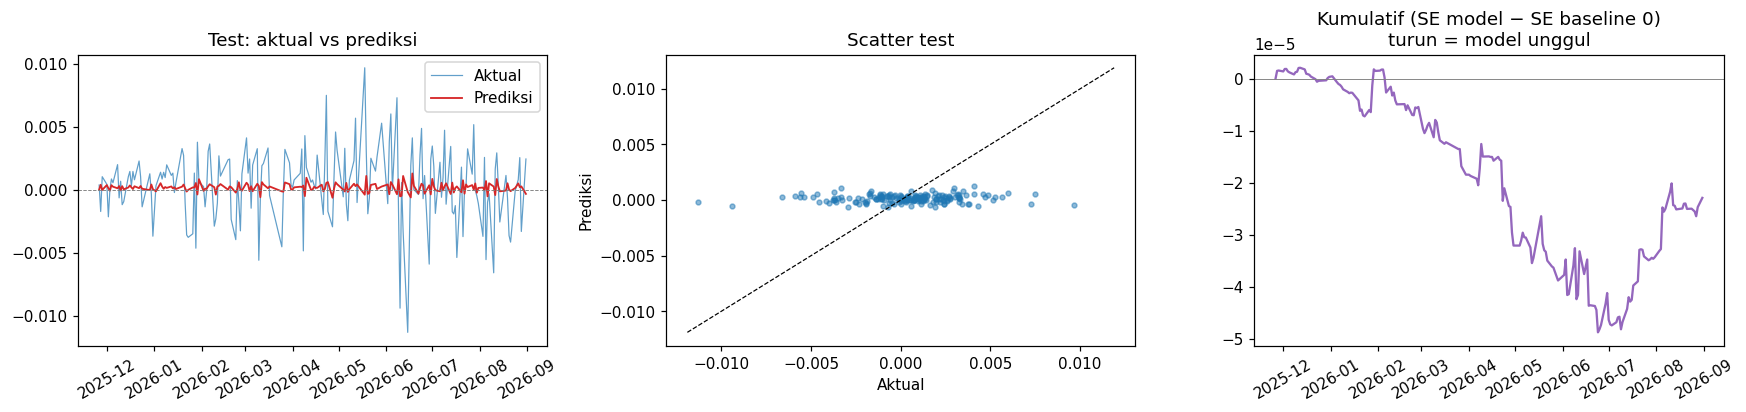

In [25]:
best_key = tuple(best_per_set.sort_values("val_RMSE").iloc[0][["Set fitur", "Model"]])
best_pipe, best_params = fitted[best_key]
pred_te = test_preds[best_key]
print("Konfigurasi terbaik (berdasarkan RMSE validasi):", best_key, best_params)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(test["Tanggal"], y_te, lw=.8, alpha=.7, label="Aktual")
axes[0].plot(test["Tanggal"], pred_te, lw=1.2, color="tab:red", label="Prediksi")
axes[0].axhline(0, color="gray", lw=.6, ls="--"); axes[0].legend(); axes[0].set_title("Test: aktual vs prediksi")

axes[1].scatter(y_te, pred_te, s=10, alpha=.5)
lim = np.abs(np.r_[y_te, pred_te]).max() * 1.05
axes[1].plot([-lim, lim], [-lim, lim], "k--", lw=.8)
axes[1].set_xlabel("Aktual"); axes[1].set_ylabel("Prediksi"); axes[1].set_title("Scatter test")

# Selisih kumulatif galat kuadrat vs baseline return=0 (naik = model lebih buruk)
cum = np.cumsum((y_te - pred_te) ** 2 - y_te ** 2)
axes[2].plot(test["Tanggal"], cum, color="tab:purple")
axes[2].axhline(0, color="gray", lw=.6)
axes[2].set_title("Kumulatif (SE model − SE baseline 0)\nturun = model unggul")
for ax in axes[[0, 2]]:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

In [26]:
# Permutation importance pada TEST (per kolom input; teks dihitung sebagai satu kelompok)
cols, use_text = FEATURE_SETS[best_key[0]]
X_imp = test[cols + ([TEXT_COL] if use_text else [])]
imp = permutation_importance(best_pipe, X_imp, y_te, n_repeats=20, random_state=RANDOM_STATE,
                             scoring="neg_root_mean_squared_error")
imp_df = (pd.DataFrame({"fitur": X_imp.columns, "kenaikan_RMSE": imp.importances_mean, "std": imp.importances_std})
            .sort_values("kenaikan_RMSE", ascending=False))
imp_df.head(15).round(7)

,fitur,kenaikan_RMSE,std
1,ret_lag1,0.000023,0.000017
0,ret,0.000018,0.000023
2,ret_lag2,0.000000,0.000000
4,ret_roll_mean5,0.000000,0.000000
5,ret_roll_std5,0.000000,0.000000
6,ret_roll_std20,0.000000,0.000000
3,ret_lag3,-0.000002,0.000002


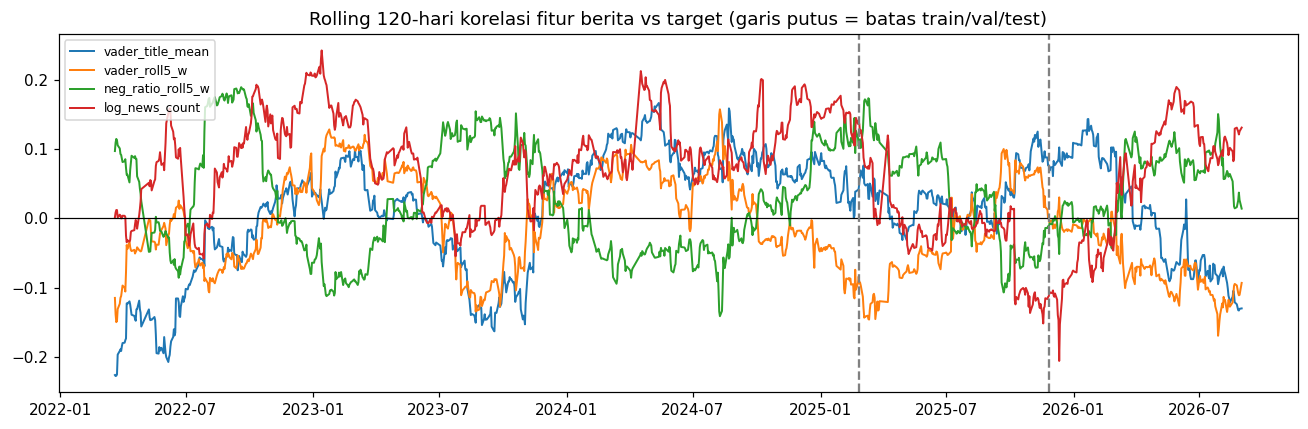

In [27]:
# Stabilitas hubungan: rolling korelasi 120 hari antara fitur berita dan target
WINDOW = 120
fig, ax = plt.subplots(figsize=(12, 4))
for f in ["vader_title_mean", "vader_roll5_w", "neg_ratio_roll5_w", "log_news_count"]:
    ax.plot(model_df["Tanggal"], model_df[f].rolling(WINDOW).corr(model_df["target"]), lw=1.3, label=f)
ax.axhline(0, color="black", lw=.8)
for d in (val["Tanggal"].min(), test["Tanggal"].min()):
    ax.axvline(d, color="gray", ls="--")
ax.set_title(f"Rolling {WINDOW}-hari korelasi fitur berita vs target (garis putus = batas train/val/test)")
ax.legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

## 12. Simpan hasil

In [28]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
keep = ["Tanggal", "Kurs Jual", "Kurs Beli", "kurs_mid"] + FEAT_RET + FEAT_NEWS + [TEXT_COL, "target"]
for name, d in [("train", train), ("val", val), ("test", test)]:
    d[keep].to_csv(OUT_DIR / f"{name}.csv", index=False, date_format="%Y-%m-%d")
news[["ts_wib", "rate_date", "url_clean", "keywords_all", "section", "title_clean",
      "vader_title", "vader_summary"]].to_csv(OUT_DIR / "news_clean.csv", index=False)
results.to_csv(OUT_DIR / "model_results.csv", index=False)
wf_res.to_csv(OUT_DIR / "walkforward_results.csv", index=False)
joblib.dump(best_pipe, OUT_DIR / "best_pipeline.joblib")
print("Tersimpan di", OUT_DIR.resolve())

Tersimpan di D:\uni - 5th sem\lecture\NLP\tugas 1\nlpproject-grestercinta\data\processed


## 13. Ringkasan otomatis

In [29]:
a = wf_res.set_index("Set fitur")
print(f"Periode out-of-sample walk-forward: {model_df['Tanggal'].iloc[i_tr].date()} -> {model_df['Tanggal'].iloc[-1].date()} ({len(oos_idx)} hari)")
for fs, r in a.iterrows():
    print(f"- {fs:<30} skill vs return=0: {r['skill_vs_zero_%']:+.2f}% | BalAcc {r['BalAcc']:.3f} "
          f"| DM p={r['DM_p']:.3f} -> {verdict_dm(r['DM_stat'], r['DM_p'])} dibanding return=0")

Periode out-of-sample walk-forward: 2025-02-26 -> 2026-08-31 (355 hari)
- A. Return saja                 skill vs return=0: +0.55% | BalAcc 0.505 | DM p=0.475 -> tidak berbeda signifikan dibanding return=0
- B. Return + Sentimen           skill vs return=0: +0.50% | BalAcc 0.509 | DM p=0.586 -> tidak berbeda signifikan dibanding return=0
- C. Return + Sentimen + Topik   skill vs return=0: +0.14% | BalAcc 0.510 | DM p=0.884 -> tidak berbeda signifikan dibanding return=0
- D. Berita saja                 skill vs return=0: +0.23% | BalAcc 0.500 | DM p=0.425 -> tidak berbeda signifikan dibanding return=0


## 14. Kesimpulan & keterbatasan

*(Isi berdasarkan angka di atas. Tulis apa adanya: hasil "berita tidak menambah daya prediksi" tetap temuan yang valid.)*

**Jawaban pertanyaan penelitian.**
- Apakah set B/C (dengan berita) mengungguli set A (return saja) di walk-forward? Berapa selisih RMSE-nya, dan apakah signifikan (DM)?
- Apakah ada model yang mengalahkan baseline return = 0? Jika tidak, ini konsisten dengan hipotesis pasar efisien / random walk untuk kurs harian.
- Bandingkan korelasi **hari yang sama** vs **t+1** (bagian 8): jika berita berkorelasi dengan return hari yang sama tetapi tidak dengan t+1, berarti pasar bereaksi cepat dan informasi berita sudah tercermin sebelum hari berikutnya.

**Keterbatasan.**
1. Jam penetapan kurs (`RATE_FIX_TIME`) diasumsikan; hasil sensitif terhadap pilihan ini. Uji juga dengan nilai lain.
2. Cakupan berita tidak merata antar tahun (bias hasil pencarian CNBC), sehingga fitur berita tidak stasioner.
3. VADER tidak dirancang untuk teks keuangan/geopolitik; banyak judul mendapat skor 0.
4. Hanya satu sumber berita berbahasa Inggris. Berita domestik (kebijakan BI, neraca perdagangan) tidak tercakup.
5. Tidak ada variabel makro pembanding (DXY, yield UST, harga minyak, VIX) yang mungkin menjelaskan kurs jauh lebih baik.

**Saran pengembangan.** FinBERT / Loughran–McDonald untuk sentimen, indeks GPR (Caldara & Iacoviello)
sebagai pembanding, variabel kontrol makro, dan target volatilitas (|return|) yang umumnya lebih mudah diprediksi dari berita daripada arah.